In [1]:
import os
import sys
import requests
import datetime as dt
import numpy as np
from dotenv import load_dotenv
from pathlib import Path
import requests
import pandas as pd
import talib as ta
import plotly.graph_objs as go

import ipywidgets as widgets
from ipywidgets import Dropdown, Text, Button, Output
from IPython.display import display

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

#### WTIの時系列データを取得

In [3]:
wti = 'CL=F'
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
response = request_api.update_commodity_timeseries_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [4]:
wti_df = request_api.get_commodity_time_series_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
wti_df.head()

取得件数: 6560


,id,commodity_id,commodity_code,commodity_market,date,open,high,low,close,adj_close,...,rci26,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,6530,2,CL=F,None,2000-08-23,32.049999,32.799999,31.950001,31.950001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,6531,2,CL=F,None,2000-08-24,31.629999,32.240002,31.400000,31.900000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,6532,2,CL=F,None,2000-08-25,32.049999,32.099998,31.320000,31.700001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,6533,2,CL=F,None,2000-08-28,32.869999,32.919998,31.860001,32.040001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,6534,2,CL=F,None,2000-08-29,32.720001,33.029999,32.560001,32.820000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500の時系列データを取得

In [5]:
sp500 = '^GSPC'

response = request_api.update_stock_timeseries_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [6]:
sp_timeseries_df = request_api.get_stock_time_series_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
sp_timeseries_df.head()

取得件数: 7014


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1064856,^GSPC,None,1998-11-17,1139.319946,1151.709961,1129.670044,1135.869995,705200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1064857,^GSPC,None,1998-11-18,1144.479980,1144.520020,1133.069946,1139.319946,652510000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1064858,^GSPC,None,1998-11-19,1152.609985,1155.099976,1144.420044,1144.479980,671000000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1064859,^GSPC,None,1998-11-20,1163.550049,1163.550049,1152.609985,1152.609985,721200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1064860,^GSPC,None,1998-11-23,1188.209961,1188.209961,1163.550049,1163.550049,774100000,1147.165991,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### ENBの時系列データを取得

In [7]:
enb = 'ENB'

response = request_api.update_stock_timeseries_data(
    code=enb,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [8]:
enb_timeseries_df = request_api.get_stock_time_series_data(
    code=enb,
    market=None,
    start=start,
    end=end
)
enb_timeseries_df

取得件数: 7014


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1153613,ENB,None,1998-11-17,1.541317,1.541317,1.541317,1.541317,800,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1153614,ENB,None,1998-11-18,1.554491,1.554491,1.554491,1.554491,3200,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1153615,ENB,None,1998-11-19,1.594012,1.598403,1.563273,1.563273,24800,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1153616,ENB,None,1998-11-20,1.598403,1.598403,1.598403,1.598403,4000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1153617,ENB,None,1998-11-23,1.598403,1.598403,1.598403,1.598403,0,1.571178,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7009,1160622,ENB,None,2026-10-01,46.270000,46.419998,45.720001,46.250000,5087900,46.802000,...,47.354944,-94.587211,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7010,1160623,ENB,None,2026-10-02,45.970001,46.520000,45.700001,46.189999,6608900,46.585999,...,47.140120,-94.740886,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7011,1160624,ENB,None,2026-10-05,46.040001,46.380001,45.490002,45.910000,5186200,46.384000,...,46.917281,-94.860412,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7012,1160625,ENB,None,2026-10-06,46.540001,46.580002,45.820000,46.000000,3995400,46.239999,...,46.723871,-94.945787,False,NaN,NaN,NaN,NaN,NaN,NaN,False


In [9]:
def stock_prices_and_oil_prices(
        code: str,
        name: str,
        start: str,
        end: str,
        df_sp: pd.DataFrame | None = None,
        df_wti: pd.DataFrame | None = None,
        #df_silver: pd.DataFrame | None = None,
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=None,
        start=start,
        end=end
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # WTI原油価格を統合
    if df_wti is not None:
        df_wti_tmp = df_wti.copy() if df_wti is not None else pd.DataFrame()
        if "date" not in df_wti_tmp.columns:
            df_wti_tmp = df_wti_tmp.reset_index()
        df_wti_tmp["date"] = pd.to_datetime(df_wti_tmp["date"])
        df_wti_tmp = df_wti_tmp.set_index("date")
        df_wti_tmp = df_wti_tmp.loc[start:end]

    # 株価時系列データを整形
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA50_SP"] = df_sp_tmp["ma50"].reindex(df.index)
        df["MA200_SP"] = df_sp_tmp["ma200"].reindex(df.index)
    if df_wti is not None:
        df["MA50_WTI"] = df_wti_tmp["ma50"].reindex(df.index)
        df["MA200_WTI"] = df_wti_tmp["ma200"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end,
        ma5=False,
        ma25=False,
        ma50=True,
        ma100=False,
        ma150=False,
        ma200=True,
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / WTI",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_SP"],
                name="SP_MA50",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_SP"],
                name="SP_MA200",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- WTI（右軸） ---
    if df_wti is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_WTI"],
                name="WTI_MA50",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_WTI"],
                name="WTI_MA200",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    return fig

In [10]:
name = "Enbridge Inc."
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=enb,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=wti_df
)
fig.show()

取得件数: 649


In [11]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{enb}_{start}_{end}.png"
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/ENB_2025-01-01_2026-10-08.png


#### 株価のみのチャート

In [12]:
name = "Enbridge Inc."
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
#end = dt.datetime(2026, 4, 17).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=enb,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=None
)
fig.show()

取得件数: 649


#### 時系列データを保存

In [13]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{enb}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"

df = enb_timeseries_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc['2026-01-01':end]
df.to_csv(output_path)
df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,6822,1160435,ENB,None,46.250725,46.404509,45.597140,46.058493,3117800,45.887409,...,45.283621,23.145223,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-05,6823,1160436,ENB,None,44.770550,46.125777,44.232302,46.068106,8362400,45.970068,...,45.287519,22.632972,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-06,6824,1160437,ENB,None,43.924732,45.058894,43.761334,44.876272,8396400,45.814361,...,45.207312,15.273628,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,6825,1160438,ENB,None,43.472988,44.078516,43.396098,43.828614,4661400,45.401064,...,45.008394,7.000768,False,NaN,45.672112,NaN,-0.10459,NaN,NaN,False
2026-01-08,6826,1160439,ENB,None,43.530659,43.799781,43.280757,43.444155,6166200,44.855128,...,44.789415,2.868608,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### Fibonacci Extension

{'fib_levels_down': {'1.000': np.float64(45.4900016784668),
  '1.272': np.float64(42.180621805919785),
  '1.382': np.float64(40.84226965158092),
  '1.618': np.float64(37.97089593863572)},
 'fib_levels_up': {'1.272': np.float64(60.96621931773076),
  '1.382': np.float64(62.304571472069625),
  '1.618': np.float64(65.17594518501483),
  '2.000': np.float64(69.8236772119007)},
 'swing_high': np.float64(57.65683944518375),
 'swing_low': np.float64(45.4900016784668),
 'df_with_fib':           date  index       id stock_code stock_market       open       high  \
 0   2026-01-02   6822  1160435        ENB         None  46.250725  46.404509   
 1   2026-01-05   6823  1160436        ENB         None  44.770550  46.125777   
 2   2026-01-06   6824  1160437        ENB         None  43.924732  45.058894   
 3   2026-01-07   6825  1160438        ENB         None  43.472988  44.078516   
 4   2026-01-08   6826  1160439        ENB         None  43.530659  43.799781   
 ..         ...    ...      ...    

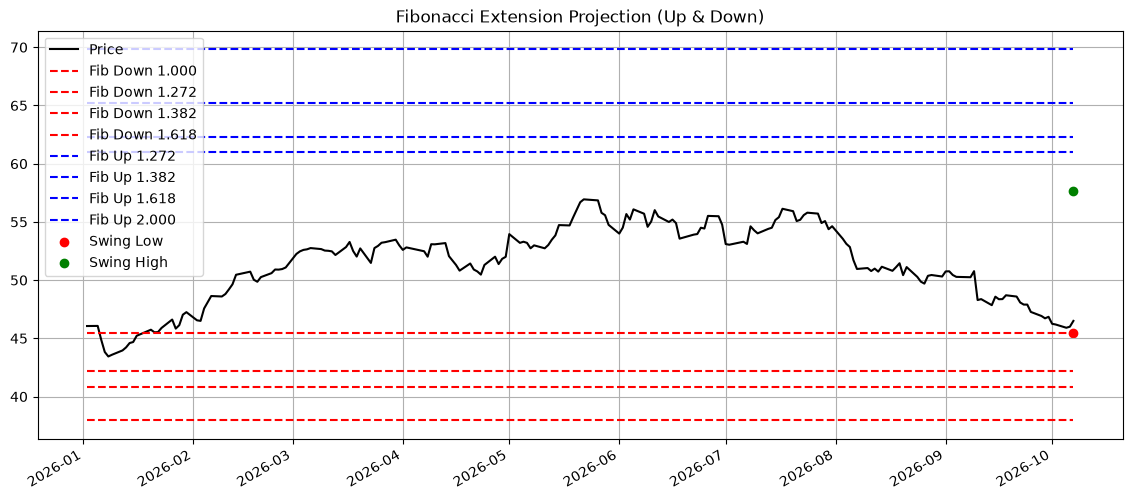

In [14]:
fib_result = fibonacci_extension.compute_fibonacci_extension(df.copy().reset_index())
fib_result

In [15]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{enb}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")

#### 財務データ

In [16]:
response = request_api.update_corp_finance_data(
    code=enb,
    market=None
)
response

{'result': True}

In [17]:
enb_financials_data = request_api.get_corp_financials_data(code=enb, market=None)
enb_balance_sheet_data = request_api.get_corp_balance_sheet_data(code=enb, market=None)
enb_cash_flow_data = request_api.get_corp_cash_flow_data(code=enb, market=None)
enb_earnings_data = request_api.get_corp_earnings_data(code=enb, market=None)
enb_quarterly_earnings_data = request_api.get_corp_quarterly_earnings_data(code=enb, market=None)

In [18]:
# ４年分の財務データ
enb_financials_data_df = pd.DataFrame(enb_financials_data['results'])
# ４年分のバランスシート
enb_balance_sheet_data_df = pd.DataFrame(enb_balance_sheet_data['results'])
# ４年分のキャッシュフロー
enb_cash_flow_data_df = pd.DataFrame(enb_cash_flow_data['results'])
# ４年分の収益データ
enb_earnings_data_df = pd.DataFrame(enb_earnings_data['results'])
# ４年分の四半期収益データ
enb_quarterly_earnings_data_df = pd.DataFrame(enb_quarterly_earnings_data['results'])

In [19]:
"""
◆ 1. 株価・市場データ
• 現在株価（Price）
• 時価総額（Market Cap）
• 出来高（Volume）
• 52週高値・安値
• Beta（ボラティリティ指標）ß
"""
stock_prices_market_data.stock_prices_and_market_data(
    code=enb,
    market=None,
    bs_df=enb_balance_sheet_data_df
)

取得件数: 461
取得件数: 461
取得件数: 460
取得件数: 460
取得件数: 458
取得件数: 458
取得件数: 459
取得件数: 459
取得件数: 458
取得件数: 458


,close,market_cap,shares_outstanding,higher_rate_par_52_weeks,lower_rate_par_52_weeks,beta
0,24.823840,NaN,NaN,32.025811,14.940642,0.943184
1,25.688703,5.201962e+10,2.025000e+09,36.915124,25.231762,0.671043
2,33.184123,7.053532e+10,2.125574e+09,36.915124,26.091628,0.732604
3,30.993124,6.750167e+10,2.177956e+09,40.582872,26.091628,0.583799
4,31.478983,6.868714e+10,2.182000e+09,48.576721,28.724572,0.527120


In [20]:
"""
◆ 2. 財務データ（Financials）+ EPS（Earnings Per Share）+ PBR（Price-to-Book Ratio）
• 売上高（Revenue）
• 営業利益（Operating Income）
• 純利益（Net Income）
• EBITDA（企業による）
• 総資産（Total Assets）
• 総負債（Total Liabilities）
• 現金（Cash）
• 希釈EPS（Diluted EPS）
• 基本EPS（Basic EPS）
• 営業キャッシュフロー（Operating Cash Flow）
• フリーキャッシュフロー（Free Cash Flow）
"""
financial_df = financial.calc_financial(
    code = enb,
    market = None,
)
financial_df.to_markdown()

取得件数: 6940


'|    | date                |      revenue |    earnings |   total_assets |    total_debt |   cash_and_cash_equivalents |     EBITDA |   operating_income |   basic_eps |   diluted_eps |   operating_cash_flow |   free_cash_flow |\n|---:|:--------------------|-------------:|------------:|---------------:|--------------:|----------------------------:|-----------:|-------------------:|------------:|--------------:|----------------------:|-----------------:|\n|  0 | 2021-12-31 00:00:00 | nan          | nan         |  nan           | nan           |                 nan         | 0          |       nan          |      nan    |        nan    |          nan          |      nan         |\n|  1 | 2022-12-31 00:00:00 |   5.3309e+10 |   3.003e+09 |    1.79608e+11 |   8.098e+10   |                   8.61e+08  | 1.2083e+10 |         8.184e+09  |        1.28 |          1.28 |            1.123e+10  |        6.409e+09 |\n|  2 | 2023-12-31 00:00:00 |   4.3649e+10 |   6.191e+09 |    1.80317e+11 |   8.1199